Number of keypoints: 791
Descriptor shape: (791, 128)
Descriptor length: 128


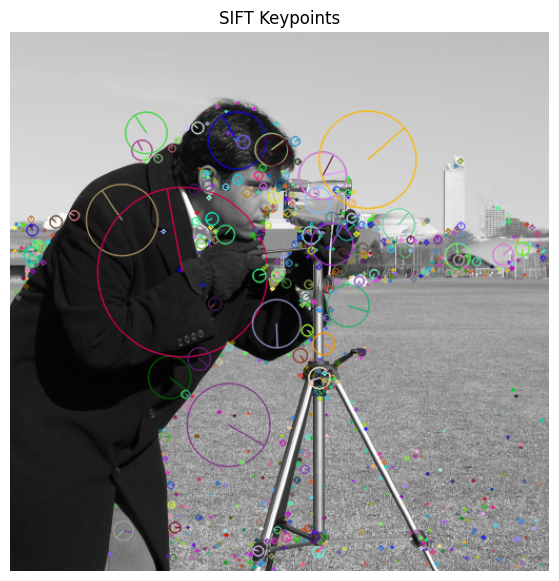

In [6]:
import cv2
import matplotlib.pyplot as plt
from skimage import data

# Load grayscale image
image = data.camera().astype("uint8")

# Create SIFT detector
sift = cv2.SIFT_create()

# Detect keypoints and compute descriptors
keypoints, descriptors = sift.detectAndCompute(
    image, None
)

# Draw keypoints
output = cv2.drawKeypoints(
    image,
    keypoints,
    None,
    flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
)

# Print information
print("Number of keypoints:", len(keypoints))

if descriptors is not None:
    print("Descriptor shape:", descriptors.shape)
    print("Descriptor length:",
          descriptors.shape[1])

# Display
plt.figure(figsize=(10, 7))
plt.imshow(output, cmap="gray")
plt.title("SIFT Keypoints")
plt.axis("off")
plt.show()


In [4]:
# SIFT
sift = cv2.SIFT_create()
kp1, des1 = sift.detectAndCompute(img1, None)
kp2, des2 = sift.detectAndCompute(img2, None)

# Brute-Force matcher using L2 distance
bf = cv2.BFMatcher(cv2.NORM_L2)
matches = bf.knnMatch(des1, des2, k=2)

# Lowe ratio test
good_matches = []
for m, n in matches:
    if m.distance < 0.75 * n.distance:
        good_matches.append(m)

# Draw matches
result = cv2.drawMatches(
    img1, kp1, img2, kp2, good_matches, None,
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

print("Keypoints in image 1:", len(kp1))
print("Keypoints in image 2:", len(kp2))
print("Good matches:", len(good_matches))



Keypoints in image 1: 791
Keypoints in image 2: 866
Good matches: 476


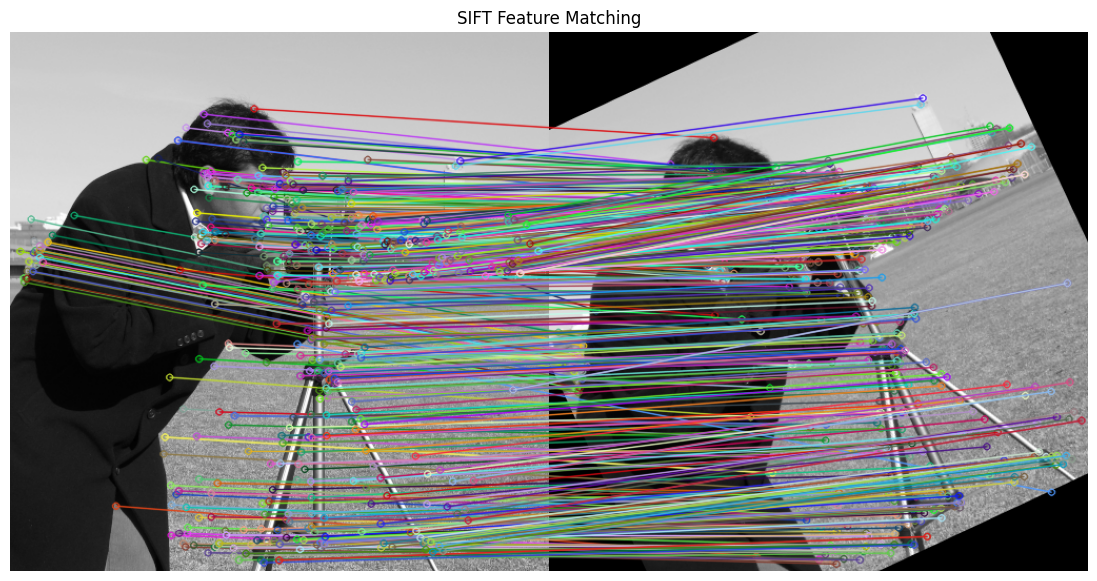

In [5]:
plt.figure(figsize=(14, 7))
plt.imshow(result, cmap="gray")
plt.title("SIFT Feature Matching")
plt.axis("off")
plt.show()